In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle (5).json


{'kaggle (5).json': b'{"username":"nirmalbairwa","key":"KGAT_f4548fd812cb7e1ed9ce07d4b570dc70"}'}

In [ ]:
! mkdir -p ~/.kaggle
!cp "kaggle.json" ~/.kaggle/kaggle.json

In [ ]:
# Security ke liye permission set karna (Sirf aap padh sakein)
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets list

ref                                                                 title                                                     size  lastUpdated                 downloadCount  voteCount  usabilityRating  
------------------------------------------------------------------  --------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
algozee/teenager-menthal-healy                                      Social Media Impact on Teen Mental Health                16190  2026-04-05 08:04:21.823000          13241        289                1  
nalisha/job-salary-prediction-dataset                               Job Salary Prediction Dataset                          3144815  2026-03-16 19:54:33.843000          15709        344                1  
mubashirsidiki/student-academic-performance-500-students            Student Academic Performance - 500 Students               6413  2026-04-07 14:23:47.547000           3497         73

In [ ]:
! kaggle datasets download -d vipoooool/new-plant-diseases-dataset

Dataset URL: https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset
License(s): copyright-authors
new-plant-diseases-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
!unzip -q new-plant-diseases-dataset.zip

replace New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train/Apple___Apple_scab/00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
!ls

In [ ]:
import zipfile

In [ ]:
zip_ref = zipfile.ZipFile("/content/new-plant-diseases-dataset.zip")
zip_ref.extractall("/content")
zip_ref.close()

In [ ]:
train_data_dir = "/content/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train"
validation_data_dir = "/content/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid"

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

058d5e64-2c57-45ba-94cb-ac83fd1885a0___FREC_Scab 3181.JPG


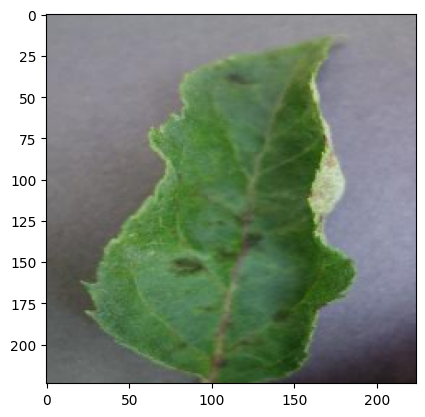

In [ ]:
# path of the Folder
folder = "/content/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train/Apple___Apple_scab"
images = os.listdir(folder)

for file in images:
    path = os.path.join(folder, file)
    print(file)

    img = cv2.imread(path)

    img = cv2.resize(img, (224, 224))

    img1 = np.reshape(img, (1, 224, 224, 3))
    img2 = np.array(img1, dtype="float32", ndmin=4)

    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.show()

    break

In [ ]:
for class_label in os.walk("/content/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train"):
  print('class_label',class_label)

class_label ('/content/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train', ['Cherry_(including_sour)___Powdery_mildew', 'Peach___healthy', 'Apple___Cedar_apple_rust', 'Cherry_(including_sour)___healthy', 'Potato___Early_blight', 'Strawberry___healthy', 'Potato___Late_blight', 'Blueberry___healthy', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Orange___Haunglongbing_(Citrus_greening)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Tomato___Bacterial_spot', 'Pepper,_bell___Bacterial_spot', 'Apple___healthy', 'Grape___healthy', 'Tomato___Septoria_leaf_spot', 'Tomato___Late_blight', 'Tomato___Target_Spot', 'Pepper,_bell___healthy', 'Apple___Black_rot', 'Tomato___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Potato___healthy', 'Corn_(maize)___Northern_Leaf_Blight', 'Squash___Powdery_mildew', 'Corn_(maize)___Common_rust_', 'Tomato___Early_blight', 'Grape___Esca_(Black_Measles)', 'Strawberry___L

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
train_datagen = ImageDataGenerator(
    rescale = 1./255,
   rotation_range=30,
   shear_range = 0.3,
   zoom_range = 0.3,
    horizontal_flip=True,
    fill_mode = "nearest"
)

validation_datagen = ImageDataGenerator(
    rescale = 1./255
)

In [ ]:
train_generator = train_datagen.flow_from_directory(
    train_data_dir,
   # target_size = (32),
  #  batch_size = 32,
    color_mode = "grayscale",
    class_mode = "categorical",
    shuffle=True
)


validation_generator = validation_datagen.flow_from_directory(
    validation_data_dir,
    target_size = (256,256),
    batch_size = 32,
    color_mode = "grayscale",
    class_mode = "categorical",
    shuffle=True
)

Found 70295 images belonging to 38 classes.
Found 17572 images belonging to 38 classes.


In [ ]:
class_label = ['Apple___Apple_scab','Apple___Black_rot','Apple___Cedar_apple_rust','Apple___healthy','Blueberry___healthy','Cherry_(including_sour)___Powdery_mildew','Cherry_(including_sour)___healthy','Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot','Corn_(maize)___Common_rust_','Corn_(maize)___Northern_Leaf_Blight','Corn_(maize)___healthy','Grape___Black_rot','Grape___Esca_(Black_Measles)','Grape___Leaf_blight_(Isariopsis_Leaf_Spot)','Grape___healthy',
              'Orange___Haunglongbing_(Citrus_greening)','Peach___Bacterial_spot','Peach___healthy','Pepper,_bell___Bacterial_spot','Pepper,_bell___healthy','Potato___Early_blight','Potato___Late_blight','Potato___healthy','Raspberry___healthy','Soybean___healthy','Squash___Powdery_mildew','Strawberry___Leaf_scorch','Strawberry___healthy','Tomato___Bacterial_spot','Tomato___Early_blight','Tomato___Late_blight','Tomato___Leaf_Mold','Tomato___Septoria_leaf_spot','Tomato___Spider_mites Two-spotted_spider_mite','Tomato___Target_Spot','Tomato___Tomato_Yellow_Leaf_Curl_Virus','Tomato___Tomato_mosaic_virus','Tomato___healthy' ]

In [ ]:
len(class_label)

38

In [ ]:
img,labels = train_generator.__next__()

In [ ]:
print(img)

[[[[3.8505769e-01]
   [3.9759958e-01]
   [4.4073570e-01]
   ...
   [7.1430677e-01]
   [8.1700104e-01]
   [7.5213361e-01]]

  [[4.7198325e-01]
   [4.2194536e-01]
   [3.7190747e-01]
   ...
   [8.0046451e-01]
   [8.3304614e-01]
   [6.1735487e-01]]

  [[4.3747544e-01]
   [4.6680796e-01]
   [4.5883304e-01]
   ...
   [8.1650966e-01]
   [7.5626159e-01]
   [5.1531434e-01]]

  ...

  [[4.1733888e-01]
   [3.6092746e-01]
   [3.6388263e-01]
   ...
   [4.3623880e-01]
   [4.7069228e-01]
   [5.4488635e-01]]

  [[3.9400050e-01]
   [3.4734610e-01]
   [3.7992769e-01]
   ...
   [4.5422336e-01]
   [4.4387069e-01]
   [4.3351805e-01]]

  [[3.6191034e-01]
   [3.6339116e-01]
   [4.1311142e-01]
   ...
   [3.4818184e-01]
   [4.1202328e-01]
   [4.5150262e-01]]]


 [[[2.9940972e-01]
   [5.6791323e-01]
   [6.0448951e-01]
   ...
   [6.4781624e-01]
   [6.4013875e-01]
   [5.9086210e-01]]

  [[4.6967885e-01]
   [4.6365339e-01]
   [4.5024952e-01]
   ...
   [6.1424017e-01]
   [5.8781534e-01]
   [6.0717529e-01]]

  [[5.4

In [ ]:
import keras
import tensorflow
from matplotlib import pyplot
import numpy as np

# Get one batch of images and labels from the generator
images, labels = train_generator.__next__()

# Display the first 9 images from the batch
num_images_to_display = 9
for i in range(num_images_to_display):
  pyplot.subplot(3, 3, i + 1) # Changed subplot dimensions to 3x3
  pyplot.axis('off')
  # Images from a grayscale generator will have shape (height, width, 1).
  # imshow can handle this, but explicitly squeezing and setting cmap='gray' is good practice.
  pyplot.imshow(np.squeeze(images[i]), cmap='gray')
pyplot.show()

In [ ]:
img = cv2.imread("/content/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train/Apple___Apple_scab/0b4a52e3-e15e-4117-b2e8-7cdb5dca3ce9___FREC_Scab 3137_90deg.JPG")
#plt.imshow(img)
GRAY = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
plt.imshow(GRAY)
plt.imshow(img)
plt.title("apple_Apple_scab disease")
plt.plot()

In [ ]:
# Create a cnn model


model = Sequential()

model.add(Conv2D(32,kernel_size=(3,3),activation='relu',input_shape=(48,48,1)))

model.add(Conv2D(64,kernel_size=(3,3),activation="relu"))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Conv2D(128,kernel_size=(3,3),activation="relu"))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Conv2D(256,kernel_size=(3,3),activation="relu"))
model.add(MaxPooling2D(pool_size=(2,2)))


model.add(Flatten())
model.add(Dense(512,activation='relu'))

model.add(Dense(38,activation="softmax"))

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 46, 46, 32)        320       
                                                                 
 conv2d_1 (Conv2D)           (None, 44, 44, 64)        18496     
                                                                 
 max_pooling2d (MaxPooling2D  (None, 22, 22, 64)       0         
 )                                                               
                                                                 
 conv2d_2 (Conv2D)           (None, 20, 20, 128)       73856     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 10, 10, 128)      0         
 2D)                                                             
                                                                 
 conv2d_3 (Conv2D)           (None, 8, 8, 256)         2

In [ ]:
model.compile(optimizer="adam",loss="categorical_crossentropy",metrics=['accuracy'])

In [ ]:
train_path = "/content/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train"
test_path = "/content/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid"

In [ ]:
num_train_imgs = 0

for root,dirs,files in os.walk(train_path):
  num_train_imgs+=len(files)

num_test_imgs =0
for root,dirs,files in os.walk(test_path):
  num_test_imgs+=len(files)

In [ ]:
history = model.fit(train_generator,steps_per_epoch=num_train_imgs//32,epochs=5,validation_data=validation_generator,validation_steps=num_test_imgs//32)

Epoch 1/5
2196/2196 [==============================] - 144s 66ms/step - loss: 0.5919 - accuracy: 0.8070 - val_loss: 1.8010 - val_accuracy: 0.6122
Epoch 2/5
2196/2196 [==============================] - 143s 65ms/step - loss: 0.5670 - accuracy: 0.8154 - val_loss: 2.2700 - val_accuracy: 0.5528
Epoch 3/5
2196/2196 [==============================] - 141s 64ms/step - loss: 0.5351 - accuracy: 0.8239 - val_loss: 1.7985 - val_accuracy: 0.6179
Epoch 4/5
2196/2196 [==============================] - 142s 65ms/step - loss: 0.5174 - accuracy: 0.8306 - val_loss: 1.6016 - val_accuracy: 0.6476
Epoch 5/5
2196/2196 [==============================] - 143s 65ms/step - loss: 0.4997 - accuracy: 0.8354 - val_loss: 2.0350 - val_accuracy: 0.6204


<Axes: >

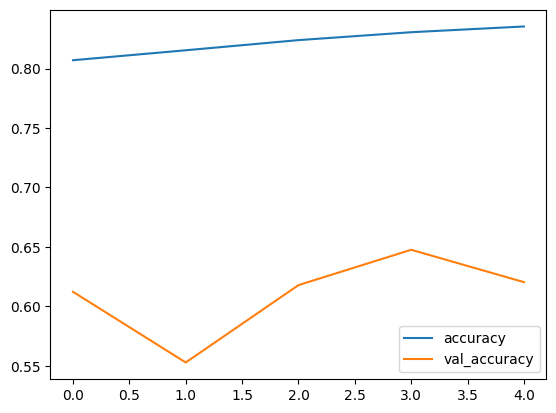

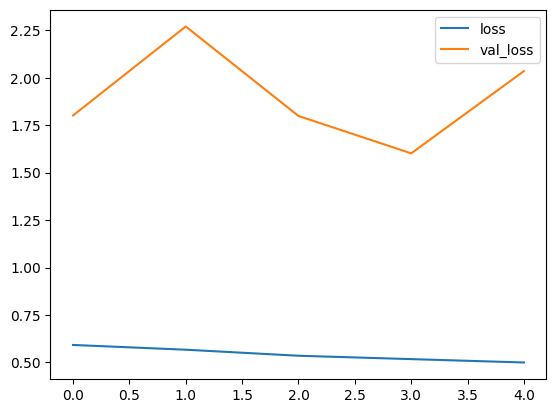

In [ ]:
history_df = pd.DataFrame(history.history)
history_df.loc[:,['accuracy','val_accuracy']].plot()
history_df.loc[:,['loss','val_loss']].plot()

1/1 [==============================] - 0s 27ms/step
Corn_(maize)___Common_rust_ Disease
8


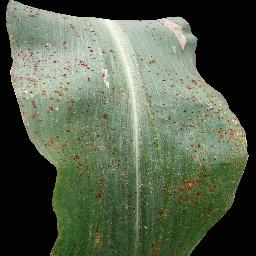

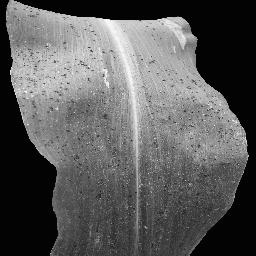

In [ ]:
frame = cv2.imread("/content/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid/Corn_(maize)___Common_rust_/RS_Rust 1576.JPG")

gray = cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY)
labels_dict = {0:'Apple___Apple_scab',1:'Apple___Black_rot',2:'Apple___Cedar_apple_rust',3:'Apple___healthy',4:'Blueberry___healthy',5:'Cherry_(including_sour)___Powdery_mildew',6:'Cherry_(including_sour)___healthy',7:'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',8:'Corn_(maize)___Common_rust_',9:'Corn_(maize)___Northern_Leaf_Blight',10:'Corn_(maize)___healthy',11:'Grape___Black_rot',12:'Grape___Esca_(Black_Measles)',13:'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',14:'Grape___healthy',
             15: 'Orange___Haunglongbing_(Citrus_greening)',16:'Peach___Bacterial_spot',17:'Peach___healthy',18:'Pepper,_bell___Bacterial_spot',19:'Pepper,_bell___healthy',20:'Potato___Early_blight',21:'Potato___Late_blight',22:'Potato___healthy',23:'Raspberry___healthy',24:'Soybean___healthy',25:'Squash___Powdery_mildew',26:'Strawberry___Leaf_scorch',27:'Strawberry___healthy',28:'Tomato___Bacterial_spot',29:'Tomato___Early_blight',30:'Tomato___Late_blight',31:'Tomato___Leaf_Mold',32:'Tomato___Septoria_leaf_spot',33:'Tomato___Spider_mites Two-spotted_spider_mite',34:'Tomato___Target_Spot',35:'Tomato___Tomato_Yellow_Leaf_Curl_Virus',36:'Tomato___Tomato_mosaic_virus',37:'Tomato___healthy' }
gray = cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY)
#RGB = cv2.cvtColor(frame,cv2.COLOR_GRAY2RGB)
resized = cv2.resize(gray,(48,48))
normalize = resized/255.0
reshaped = np.reshape(normalize,(1,48,48,1))
result = model.predict(reshaped)
label = np.argmax(result,axis=1)[0]
if (label==0):
  print("Apple__Applea_scab Disease")
if (label==1):
  print("Apple__Black_rot Disease")
if (label==2):
  print("Apple__cedar_apple_rust Disease")
if (label==3):
  print("Apple__healthy")
if (label==4):
  print("Bluberry__healthy")
if (label==5):
  print("Cherry_(including_sour)___Powdery_mildew Disease")
if (label==6):
  print("Cherry_(including_sour)___healthy")
if (label==7):
  print("Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot Disease")
if (label==8):
  print('Corn_(maize)___Common_rust_ Disease')
if (label==9):
  print("Corn_(maize)___Northern_Leaf_Blight Disease")
if (label==10):
  print("Corn_(maize)___healthy")
if (label==11):
  print("Grape___Black_rot Disease")
if (label==12):
  print("Grape___Esca_(Black_Measles) Disease")
if (label==13):
  print("Grape___Leaf_blight_(Isariopsis_Leaf_Spot Disease")
if (label==14):
  print("Grape___healthy")
if (label==15):
  print("Orange___Haunglongbing_(Citrus_greening) Disease")
if (label==16):
  print("Peach___Bacterial_spot Disease")
if (label==17):
  print("Peach___healthy")
if (label==18):
  print("Pepper,_bell___Bacterial_spot Disease")
if (label==19):
  print("Pepper,_bell___healthy")
if (label==20):
  print("Potato___Early_blight Disease")
if (label==21):
  print("Potato___Late_blight Disease")
if (label==22):
  print('Potato___healthy')
if(label==23):
  print('Raspberry___healthy')
if(label==24):
  print('Soybean___healthy')
if(label==25):
  print('Squash___Powdery_mildew Disease')
if(label==26):
  print('Strawberry___Leaf_scorch v')
if(label==27):
  print('Strawberry___healthy')
if(label==28):
  print('Tomato___Bacterial_spot Disease')
if(label==29):
  print('Tomato___Early_blight Disease')
if(label==30):
  print('Tomato___Late_blight Disease')
if(label==31):
  print('Tomato___Leaf_Mold Disease')
if(label==32):
  print('Tomato___Septoria_leaf_spot Disease')
if(label==33):
  print('Tomato___Spider_mites Two-spotted_spider_mite Disease')
if(label==34):
  print('Tomato___Target_Spot Disease')
if(label==35):
  print('Tomato___Tomato_Yellow_Leaf_Curl_Virus')
if(label==36):
  print('Tomato___Tomato_mosaic_virus')
if(label==37):
  print('Tomato___healthy')
print(label)
cv2_imshow(frame)
cv2_imshow(gray)
#cv2_imshow(RGB)

In [ ]:
## TEST 2 FOR IMAGE
frame = cv2.imread("/content/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid/Tomato___Tomato_Yellow_Leaf_Curl_Virus/057552a8-8c38-443f-b523-5ee2b428e622___UF.GRC_YLCV_Lab 09477.JPG","/content/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid/Corn_(maize)___Common_rust_/RS_Rust 1576.JPG")
gray = cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY,cv2.COLOR_GRAY2RGB)
labels_dict = {0:'Apple___Apple_scab',1:'Apple___Black_rot',2:'Apple___Cedar_apple_rust',3:'Apple___healthy',4:'Blueberry___healthy',5:'Cherry_(including_sour)___Powdery_mildew',6:'Cherry_(including_sour)___healthy',7:'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',8:'Corn_(maize)___Common_rust_',9:'Corn_(maize)___Northern_Leaf_Blight',10:'Corn_(maize)___healthy',11:'Grape___Black_rot',12:'Grape___Esca_(Black_Measles)',13:'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',14:'Grape___healthy',
             15: 'Orange___Haunglongbing_(Citrus_greening)',16:'Peach___Bacterial_spot',17:'Peach___healthy',18:'Pepper,_bell___Bacterial_spot',19:'Pepper,_bell___healthy',20:'Potato___Early_blight',21:'Potato___Late_blight',22:'Potato___healthy',23:'Raspberry___healthy',24:'Soybean___healthy',25:'Squash___Powdery_mildew',26:'Strawberry___Leaf_scorch',27:'Strawberry___healthy',28:'Tomato___Bacterial_spot',29:'Tomato___Early_blight',30:'Tomato___Late_blight',31:'Tomato___Leaf_Mold',32:'Tomato___Septoria_leaf_spot',33:'Tomato___Spider_mites Two-spotted_spider_mite',34:'Tomato___Target_Spot',35:'Tomato___Tomato_Yellow_Leaf_Curl_Virus',36:'Tomato___Tomato_mosaic_virus',37:'Tomato___healthy' }
gray = cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY,cv2.COLOR_GRAY2RGB)
#RGB = cv2.cvtColor(frame,cv2.COLOR_GRAY2RGB)
resized = cv2.resize(gray,(48,48))
normalize = resized/255.0
reshaped = np.reshape(normalize,(1,48,48,1))
result = model.predict(reshaped)
label = np.argmax(result,axis=1)[0]
if (label==0):
  print("Apple__Applea_scab Disease")
if (label==1):
  print("Apple__Black_rot Disease")
if (label==2):
  print("Apple__cedar_apple_rust Disease")
if (label==3):
  print("Apple__healthy")
if (label==4):
  print("Bluberry__healthy")
if (label==5):
  print("Cherry_(including_sour)___Powdery_mildew Disease")
if (label==6):
  print("Cherry_(including_sour)___healthy")
if (label==7):
  print("Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot Disease")
if (label==8):
  print('Corn_(maize)___Common_rust_ Disease')
if (label==9):
  print("Corn_(maize)___Northern_Leaf_Blight Disease")
if (label==10):
  print("Corn_(maize)___healthy")
if (label==11):
  print("Grape___Black_rot Disease")
if (label==12):
  print("Grape___Esca_(Black_Measles) Disease")
if (label==13):
  print("Grape___Leaf_blight_(Isariopsis_Leaf_Spot Disease")
if (label==14):
  print("Grape___healthy")
if (label==15):
  print("Orange___Haunglongbing_(Citrus_greening) Disease")
if (label==16):
  print("Peach___Bacterial_spot Disease")
if (label==17):
  print("Peach___healthy")
if (label==18):
  print("Pepper,_bell___Bacterial_spot Disease")
if (label==19):
  print("Pepper,_bell___healthy")
if (label==20):
  print("Potato___Early_blight Disease")
if (label==21):
  print("Potato___Late_blight Disease")
if (label==22):
  print('Potato___healthy')
if(label==23):
  print('Raspberry___healthy')
if(label==24):
  print('Soybean___healthy')
if(label==25):
  print('Squash___Powdery_mildew Disease')
if(label==26):
  print('Strawberry___Leaf_scorch v')
if(label==27):
  print('Strawberry___healthy')
if(label==28):
  print('Tomato___Bacterial_spot Disease')
if(label==29):
  print('Tomato___Early_blight Disease')
if(label==30):
  print('Tomato___Late_blight Disease')
if(label==31):
  print('Tomato___Leaf_Mold Disease')
if(label==32):
  print('Tomato___Septoria_leaf_spot Disease')
if(label==33):
  print('Tomato___Spider_mites Two-spotted_spider_mite Disease')
if(label==34):
  print('Tomato___Target_Spot Disease')
if(label==35):
  print('Tomato___Tomato_Yellow_Leaf_Curl_Virus')
if(label==36):
  print('Tomato___Tomato_mosaic_virus')
if(label==37):
  print('Tomato___healthy')
print(label)
cv2_imshow(frame)
cv2_imshow(gray)
#cv2_imshow(RGB)

NameError: name 'cv2' is not defined

In [ ]:
# TEST 3 For plant Disease check


1/1 [==============================] - 0s 29ms/step
Strawberry___healthy
27


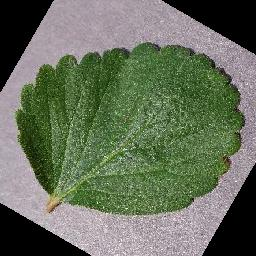

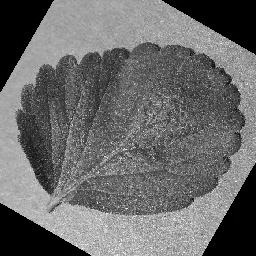

In [ ]:

## TEST 2 FOR IMAGE
frame = cv2.imread("/content/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid/Strawberry___healthy/01e591c9-e3e7-4edc-8211-13081f4d5e7a___RS_HL 1979_new30degFlipLR.JPG")

gray = cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY)
labels_dict = {0:'Apple___Apple_scab',1:'Apple___Black_rot',2:'Apple___Cedar_apple_rust',3:'Apple___healthy',4:'Blueberry___healthy',5:'Cherry_(including_sour)___Powdery_mildew',6:'Cherry_(including_sour)___healthy',7:'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',8:'Corn_(maize)___Common_rust_',9:'Corn_(maize)___Northern_Leaf_Blight',10:'Corn_(maize)___healthy',11:'Grape___Black_rot',12:'Grape___Esca_(Black_Measles)',13:'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',14:'Grape___healthy',
             15: 'Orange___Haunglongbing_(Citrus_greening)',16:'Peach___Bacterial_spot',17:'Peach___healthy',18:'Pepper,_bell___Bacterial_spot',19:'Pepper,_bell___healthy',20:'Potato___Early_blight',21:'Potato___Late_blight',22:'Potato___healthy',23:'Raspberry___healthy',24:'Soybean___healthy',25:'Squash___Powdery_mildew',26:'Strawberry___Leaf_scorch',27:'Strawberry___healthy',28:'Tomato___Bacterial_spot',29:'Tomato___Early_blight',30:'Tomato___Late_blight',31:'Tomato___Leaf_Mold',32:'Tomato___Septoria_leaf_spot',33:'Tomato___Spider_mites Two-spotted_spider_mite',34:'Tomato___Target_Spot',35:'Tomato___Tomato_Yellow_Leaf_Curl_Virus',36:'Tomato___Tomato_mosaic_virus',37:'Tomato___healthy' }
gray = cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY)
#RGB = cv2.cvtColor(frame,cv2.COLOR_GRAY2RGB)
resized = cv2.resize(gray,(48,48))
normalize = resized/255.0
reshaped = np.reshape(normalize,(1,48,48,1))
result = model.predict(reshaped)
label = np.argmax(result,axis=1)[0]
if (label==0):
  print("Apple__Applea_scab Disease")
if (label==1):
  print("Apple__Black_rot Disease")
if (label==2):
  print("Apple__cedar_apple_rust Disease")
if (label==3):
  print("Apple__healthy")
if (label==4):
  print("Bluberry__healthy")
if (label==5):
  print("Cherry_(including_sour)___Powdery_mildew Disease")
if (label==6):
  print("Cherry_(including_sour)___healthy")
if (label==7):
  print("Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot Disease")
if (label==8):
  print('Corn_(maize)___Common_rust_ Disease')
if (label==9):
  print("Corn_(maize)___Northern_Leaf_Blight Disease")
if (label==10):
  print("Corn_(maize)___healthy")
if (label==11):
  print("Grape___Black_rot Disease")
if (label==12):
  print("Grape___Esca_(Black_Measles) Disease")
if (label==13):
  print("Grape___Leaf_blight_(Isariopsis_Leaf_Spot Disease")
if (label==14):
  print("Grape___healthy")
if (label==15):
  print("Orange___Haunglongbing_(Citrus_greening) Disease")
if (label==16):
  print("Peach___Bacterial_spot Disease")
if (label==17):
  print("Peach___healthy")
if (label==18):
  print("Pepper,_bell___Bacterial_spot Disease")
if (label==19):
  print("Pepper,_bell___healthy")
if (label==20):
  print("Potato___Early_blight Disease")
if (label==21):
  print("Potato___Late_blight Disease")
if (label==22):
  print('Potato___healthy')
if(label==23):
  print('Raspberry___healthy')
if(label==24):
  print('Soybean___healthy')
if(label==25):
  print('Squash___Powdery_mildew Disease')
if(label==26):
  print('Strawberry___Leaf_scorch v')
if(label==27):
  print('Strawberry___healthy')
if(label==28):
  print('Tomato___Bacterial_spot Disease')
if(label==29):
  print('Tomato___Early_blight Disease')
if(label==30):
  print('Tomato___Late_blight Disease')
if(label==31):
  print('Tomato___Leaf_Mold Disease')
if(label==32):
  print('Tomato___Septoria_leaf_spot Disease')
if(label==33):
  print('Tomato___Spider_mites Two-spotted_spider_mite Disease')
if(label==34):
  print('Tomato___Target_Spot Disease')
if(label==35):
  print('Tomato___Tomato_Yellow_Leaf_Curl_Virus')
if(label==36):
  print('Tomato___Tomato_mosaic_virus')
if(label==37):
  print('Tomato___healthy')
print(label)
cv2_imshow(frame)
cv2_imshow(gray)
#cv2_imshow(RGB)

1/1 [==============================] - 0s 20ms/step
Peach___Bacterial_spot Disease
16


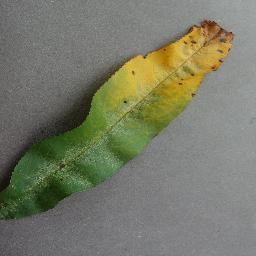

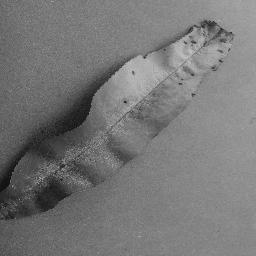

In [ ]:
# Test 4 To Detect Plant Disease

## TEST 2 FOR IMAGE
frame = cv2.imread("/content/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid/Peach___Bacterial_spot/03dcaf93-d233-4726-a973-1ce1453a0ed1___Rutg._Bact.S 2281.JPG")

gray = cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY)
labels_dict = {0:'Apple___Apple_scab',1:'Apple___Black_rot',2:'Apple___Cedar_apple_rust',3:'Apple___healthy',4:'Blueberry___healthy',5:'Cherry_(including_sour)___Powdery_mildew',6:'Cherry_(including_sour)___healthy',7:'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',8:'Corn_(maize)___Common_rust_',9:'Corn_(maize)___Northern_Leaf_Blight',10:'Corn_(maize)___healthy',11:'Grape___Black_rot',12:'Grape___Esca_(Black_Measles)',13:'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',14:'Grape___healthy',
             15: 'Orange___Haunglongbing_(Citrus_greening)',16:'Peach___Bacterial_spot',17:'Peach___healthy',18:'Pepper,_bell___Bacterial_spot',19:'Pepper,_bell___healthy',20:'Potato___Early_blight',21:'Potato___Late_blight',22:'Potato___healthy',23:'Raspberry___healthy',24:'Soybean___healthy',25:'Squash___Powdery_mildew',26:'Strawberry___Leaf_scorch',27:'Strawberry___healthy',28:'Tomato___Bacterial_spot',29:'Tomato___Early_blight',30:'Tomato___Late_blight',31:'Tomato___Leaf_Mold',32:'Tomato___Septoria_leaf_spot',33:'Tomato___Spider_mites Two-spotted_spider_mite',34:'Tomato___Target_Spot',35:'Tomato___Tomato_Yellow_Leaf_Curl_Virus',36:'Tomato___Tomato_mosaic_virus',37:'Tomato___healthy' }
gray = cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY)
#RGB = cv2.cvtColor(frame,cv2.COLOR_GRAY2RGB)
resized = cv2.resize(gray,(48,48))
normalize = resized/255.0
reshaped = np.reshape(normalize,(1,48,48,1))
result = model.predict(reshaped)
label = np.argmax(result,axis=1)[0]
if (label==0):
  print("Apple__Applea_scab Disease")
if (label==1):
  print("Apple__Black_rot Disease")
if (label==2):
  print("Apple__cedar_apple_rust Disease")
if (label==3):
  print("Apple__healthy")
if (label==4):
  print("Bluberry__healthy")
if (label==5):
  print("Cherry_(including_sour)___Powdery_mildew Disease")
if (label==6):
  print("Cherry_(including_sour)___healthy")
if (label==7):
  print("Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot Disease")
if (label==8):
  print('Corn_(maize)___Common_rust_ Disease')
if (label==9):
  print("Corn_(maize)___Northern_Leaf_Blight Disease")
if (label==10):
  print("Corn_(maize)___healthy")
if (label==11):
  print("Grape___Black_rot Disease")
if (label==12):
  print("Grape___Esca_(Black_Measles) Disease")
if (label==13):
  print("Grape___Leaf_blight_(Isariopsis_Leaf_Spot Disease")
if (label==14):
  print("Grape___healthy")
if (label==15):
  print("Orange___Haunglongbing_(Citrus_greening) Disease")
if (label==16):
  print("Peach___Bacterial_spot Disease")
if (label==17):
  print("Peach___healthy")
if (label==18):
  print("Pepper,_bell___Bacterial_spot Disease")
if (label==19):
  print("Pepper,_bell___healthy")
if (label==20):
  print("Potato___Early_blight Disease")
if (label==21):
  print("Potato___Late_blight Disease")
if (label==22):
  print('Potato___healthy')
if(label==23):
  print('Raspberry___healthy')
if(label==24):
  print('Soybean___healthy')
if(label==25):
  print('Squash___Powdery_mildew Disease')
if(label==26):
  print('Strawberry___Leaf_scorch v')
if(label==27):
  print('Strawberry___healthy')
if(label==28):
  print('Tomato___Bacterial_spot Disease')
if(label==29):
  print('Tomato___Early_blight Disease')
if(label==30):
  print('Tomato___Late_blight Disease')
if(label==31):
  print('Tomato___Leaf_Mold Disease')
if(label==32):
  print('Tomato___Septoria_leaf_spot Disease')
if(label==33):
  print('Tomato___Spider_mites Two-spotted_spider_mite Disease')
if(label==34):
  print('Tomato___Target_Spot Disease')
if(label==35):
  print('Tomato___Tomato_Yellow_Leaf_Curl_Virus')
if(label==36):
  print('Tomato___Tomato_mosaic_virus')
if(label==37):
  print('Tomato___healthy')
print(label)
cv2_imshow(frame)
cv2_imshow(gray)
#cv2_imshow(RGB)

1/1 [==============================] - 0s 24ms/step
Grape___Esca_(Black_Measles) Disease
12


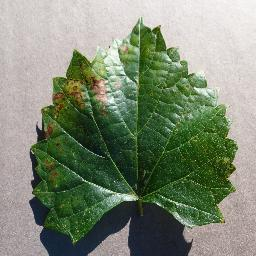

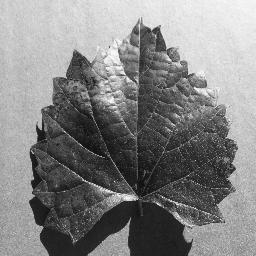

In [ ]:
# Test 5 To identify plant disease
# Test 4 To Detect Plant Disease

## TEST 2 FOR IMAGE
frame = cv2.imread("/content/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid/Grape___Esca_(Black_Measles)/023df989-ab4c-4f66-a6c8-a41c1142ab7d___FAM_B.Msls 1834_flipLR.JPG")

gray = cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY)
labels_dict = {0:'Apple___Apple_scab',1:'Apple___Black_rot',2:'Apple___Cedar_apple_rust',3:'Apple___healthy',4:'Blueberry___healthy',5:'Cherry_(including_sour)___Powdery_mildew',6:'Cherry_(including_sour)___healthy',7:'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',8:'Corn_(maize)___Common_rust_',9:'Corn_(maize)___Northern_Leaf_Blight',10:'Corn_(maize)___healthy',11:'Grape___Black_rot',12:'Grape___Esca_(Black_Measles)',13:'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',14:'Grape___healthy',
             15: 'Orange___Haunglongbing_(Citrus_greening)',16:'Peach___Bacterial_spot',17:'Peach___healthy',18:'Pepper,_bell___Bacterial_spot',19:'Pepper,_bell___healthy',20:'Potato___Early_blight',21:'Potato___Late_blight',22:'Potato___healthy',23:'Raspberry___healthy',24:'Soybean___healthy',25:'Squash___Powdery_mildew',26:'Strawberry___Leaf_scorch',27:'Strawberry___healthy',28:'Tomato___Bacterial_spot',29:'Tomato___Early_blight',30:'Tomato___Late_blight',31:'Tomato___Leaf_Mold',32:'Tomato___Septoria_leaf_spot',33:'Tomato___Spider_mites Two-spotted_spider_mite',34:'Tomato___Target_Spot',35:'Tomato___Tomato_Yellow_Leaf_Curl_Virus',36:'Tomato___Tomato_mosaic_virus',37:'Tomato___healthy' }
gray = cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY)
#RGB = cv2.cvtColor(frame,cv2.COLOR_GRAY2RGB)
resized = cv2.resize(gray,(48,48))
normalize = resized/255.0
reshaped = np.reshape(normalize,(1,48,48,1))
result = model.predict(reshaped)
label = np.argmax(result,axis=1)[0]
if (label==0):
  print("Apple__Applea_scab Disease")
if (label==1):
  print("Apple__Black_rot Disease")
if (label==2):
  print("Apple__cedar_apple_rust Disease")
if (label==3):
  print("Apple__healthy")
if (label==4):
  print("Bluberry__healthy")
if (label==5):
  print("Cherry_(including_sour)___Powdery_mildew Disease")
if (label==6):
  print("Cherry_(including_sour)___healthy")
if (label==7):
  print("Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot Disease")
if (label==8):
  print('Corn_(maize)___Common_rust_ Disease')
if (label==9):
  print("Corn_(maize)___Northern_Leaf_Blight Disease")
if (label==10):
  print("Corn_(maize)___healthy")
if (label==11):
  print("Grape___Black_rot Disease")
if (label==12):
  print("Grape___Esca_(Black_Measles) Disease")
if (label==13):
  print("Grape___Leaf_blight_(Isariopsis_Leaf_Spot Disease")
if (label==14):
  print("Grape___healthy")
if (label==15):
  print("Orange___Haunglongbing_(Citrus_greening) Disease")
if (label==16):
  print("Peach___Bacterial_spot Disease")
if (label==17):
  print("Peach___healthy")
if (label==18):
  print("Pepper,_bell___Bacterial_spot Disease")
if (label==19):
  print("Pepper,_bell___healthy")
if (label==20):
  print("Potato___Early_blight Disease")
if (label==21):
  print("Potato___Late_blight Disease")
if (label==22):
  print('Potato___healthy')
if(label==23):
  print('Raspberry___healthy')
if(label==24):
  print('Soybean___healthy')
if(label==25):
  print('Squash___Powdery_mildew Disease')
if(label==26):
  print('Strawberry___Leaf_scorch v')
if(label==27):
  print('Strawberry___healthy')
if(label==28):
  print('Tomato___Bacterial_spot Disease')
if(label==29):
  print('Tomato___Early_blight Disease')
if(label==30):
  print('Tomato___Late_blight Disease')
if(label==31):
  print('Tomato___Leaf_Mold Disease')
if(label==32):
  print('Tomato___Septoria_leaf_spot Disease')
if(label==33):
  print('Tomato___Spider_mites Two-spotted_spider_mite Disease')
if(label==34):
  print('Tomato___Target_Spot Disease')
if(label==35):
  print('Tomato___Tomato_Yellow_Leaf_Curl_Virus')
if(label==36):
  print('Tomato___Tomato_mosaic_virus')
if(label==37):
  print('Tomato___healthy')
print(label)
cv2_imshow(frame)
cv2_imshow(gray)
#cv2_imshow(RGB)